**1. Imports**

In [150]:
from eeg_framework.datasets      import *
from eeg_framework.preprocessing import *
from eeg_framework.plotting      import *
from eeg_framework.features      import *
from eeg_framework.models        import *
from eeg_framework.evaluate      import *

**2. Load Data**


In [151]:
root_dir = "data//BCI Competition 2020 - Track#3//"
subjects = [1]

epochs_train = load_bci2020_track3(root_dir=root_dir, split="train", subjects=subjects, concatenate=True)
epochs_test  = load_bci2020_track3(root_dir=root_dir, split="validation",  subjects=subjects, concatenate=True)

**3. Preprocessing**

In [152]:
from sklearn.metrics import accuracy_score

acc_vec = []

for seed in [0, 1, 2, 3, 4]:
    pipe_preprocessing = PreprocessingPipeline([
        ('filter', Filter(l_freq=None, h_freq=100.0, notch_freqs=60.0, notch_width=0.1)),
        ('ica',    ICA(random_state=seed)),
        #('ar',     AutoReject(n_jobs=4)),
        ('car',    CAR()),
        # ...
    ])

    epochs_train_f = pipe_preprocessing.fit_transform(epochs_train)
    epochs_test_f  = pipe_preprocessing.transform(epochs_test)

    pipe_feature = FeaturePipeline([
        # ('CSP', CSP()),
        ('PSD', PSDBands(bands={"B0":(0.0, 4.0), "B1": (4.0, 8.0), "B2": (8.0, 12.0), "B3": (12.0, 30.0), "B4": (30.0, 100.0)}))
        # ...
    ])

    X_train, y_train = pipe_feature.fit_transform(epochs_train_f)
    X_test, y_test = pipe_feature.transform(epochs_test_f)

    from sklearn.svm import SVC
    from sklearn.ensemble import RandomForestClassifier as RFC

    # EEGNet Example
    # clf_model = SVC(kernel='rbf', probability=True, random_state=42)
    clf_model = RFC(random_state=seed)
    clf_model.fit(X_train, y_train)

    y_pred = clf_model.predict(X_test)
    acc = accuracy_score(y_pred, y_test)
    print(acc)

    acc_vec.append(acc)

print(acc_vec)

[Pipeline] fit_transform → filter


/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing_example.py:400: RuntimeWarning: filter_length (1691) is longer than the signal (795), distortion is likely. Reduce filter length or filter a longer signal.
  data = mne.filter.notch_filter(


[Pipeline] fit_transform → ica


/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing_example.py:214: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(epochs_eeg, verbose=self.verbose)
/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing_example.py:310: RuntimeWarning: The provided Epochs instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  labels = label_components(epochs, ica, method='iclabel')
/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing_example.py:310: RuntimeWarning: The provided Epochs instance is not filtered be

  [ICLabel] component 00: eye blink (1.00)
  [ICLabel] component 01: heart beat (0.77)
  [ICLabel] component 02: eye blink (0.92)
[ICA] strategy=icalabel | components removed: [0, 1, 2]
[Pipeline] fit_transform → car
[Pipeline] applying → filter


/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing_example.py:400: RuntimeWarning: filter_length (1691) is longer than the signal (795), distortion is likely. Reduce filter length or filter a longer signal.
  data = mne.filter.notch_filter(


... (21 outputs left out)

/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing_example.py:214: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(epochs_eeg, verbose=self.verbose)
/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing_example.py:310: RuntimeWarning: The provided Epochs instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  labels = label_components(epochs, ica, method='iclabel')
/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing_example.py:310: RuntimeWarning: The provided Epochs instance is not filtered be

  [ICLabel] component 00: eye blink (1.00)
  [ICLabel] component 01: heart beat (0.75)
  [ICLabel] component 02: eye blink (0.92)
[ICA] strategy=icalabel | components removed: [0, 1, 2]
[Pipeline] fit_transform → car
[Pipeline] applying → filter


/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing_example.py:400: RuntimeWarning: filter_length (1691) is longer than the signal (795), distortion is likely. Reduce filter length or filter a longer signal.
  data = mne.filter.notch_filter(


[Pipeline] applying → ica
[Pipeline] applying → car
[FeaturePipeline] fitting → PSD
[FeaturePipeline] extracting → PSD
[PSDBands] windows=1 | bands=['B0', 'B1', 'B2', 'B3', 'B4'] | features per epoch: 320
[FeaturePipeline] extracting → PSD
[PSDBands] windows=1 | bands=['B0', 'B1', 'B2', 'B3', 'B4'] | features per epoch: 320
0.56
[0.52, 0.5, 0.5, 0.62, 0.56]


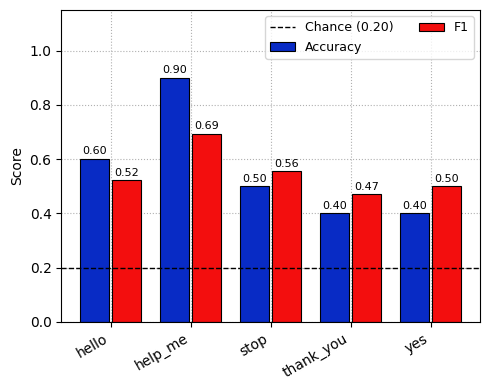

In [153]:
class_names = list(epochs_train.event_id.keys())

# Plots
fig = plot_metrics_bar(y_test, y_pred, class_names=class_names, metrics=["accuracy","f1"])
# ....

**7. Evaluation**